# Lekce 08 - Matplotlib a NumPy

Obsah:

* balíčky třetích stran
* Matplotlib: grafy ze seznamů
* graf s více osami: `plt.subplots()`
* NumPy: pole místo seznamu
* `linspace` a výpočet na celém poli
* matematické funkce a agregace
* logické masky
* 2D pole
* náhodná čísla
* časté chyby

Na konec, mimo látku: výpočet prutové konstrukce balíčkem anastruct.

## 1. Balíčky třetích stran

Moduly ze standardní knihovny (lekce 7) jsou součástí Pythonu. Dnešní dva
balíčky ne. Píšou je jiní autoři a do projektu se přidávají příkazem `uv add`:

```
uv add numpy matplotlib
```

| Balíček | K čemu |
|---|---|
| **Matplotlib** | grafy: čáry, sloupce, histogramy, mapy hodnot |
| **NumPy** | výpočty s celými řadami čísel najednou |

Oba se importují pod zkratkou, kterou používá celý svět. Když najdete příklad
na internetu, bude psát `np` a `plt`:

In [1]:
import matplotlib.pyplot as plt
import numpy as np

`matplotlib.pyplot` je modul `pyplot` z balíčku `matplotlib`, stejně jako
`stavba.geometrie` v lekci 7.

## 2. Matplotlib: grafy ze seznamů

Začneme tím, co už znáte: seznamy čísel. Funkce `plt.plot(x, y)` dostane dva
stejně dlouhé seznamy a body spojí čarou. Nakreslíme pracovní diagram
betonářské oceli, zjednodušeně jako dvě úsečky:

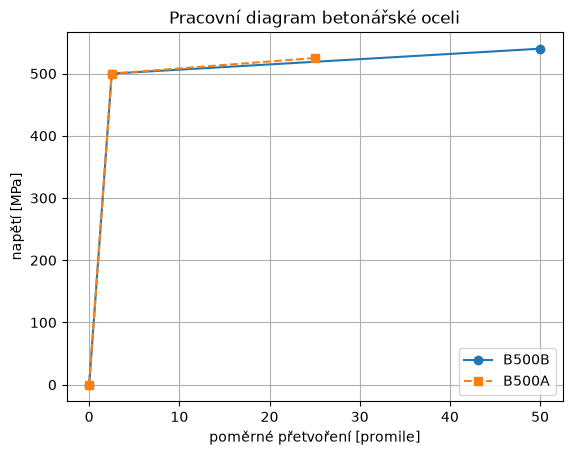

In [2]:
# B500B: mez kluzu 500 MPa pri 2.5 promile, pevnost 540 MPa pri 50 promile
eps_B = [0, 2.5, 50]          # promile
sigma_B = [0, 500, 540]       # MPa

# B500A: stejna mez kluzu, mensi tazanost
eps_A = [0, 2.5, 25]
sigma_A = [0, 500, 525]

plt.plot(eps_B, sigma_B, marker="o", label="B500B")
plt.plot(eps_A, sigma_A, marker="s", linestyle="--", label="B500A")
plt.xlabel("poměrné přetvoření [promile]")
plt.ylabel("napětí [MPa]")
plt.title("Pracovní diagram betonářské oceli")
plt.legend()
plt.grid(True)
plt.show()

Co se stalo:

* každé volání `plt.plot` přidá do grafu jednu řadu
* `label` je text do legendy, legendu zobrazí až `plt.legend()`
* `plt.show()` graf zobrazí; v notebooku se graf ukáže i bez něj na konci
  buňky, ve skriptu spuštěném přes `uv run` je `plt.show()` nutné

Vzhled čáry se nastavuje pojmenovanými argumenty:

| Argument | Příklady hodnot |
|---|---|
| `color` | `"red"`, `"black"`, `"gray"`, `"tab:blue"` |
| `linestyle` | `"-"`, `"--"`, `":"`, `"-."` |
| `marker` | `"o"`, `"s"`, `"x"`, `"^"` |
| `linewidth` | `0.5`, `2` |
| `label` | text do legendy |

Další typy grafů se volají stejně, jen jinou funkcí. **Sloupcový graf**
`plt.bar` bere popisky a výšky sloupců:

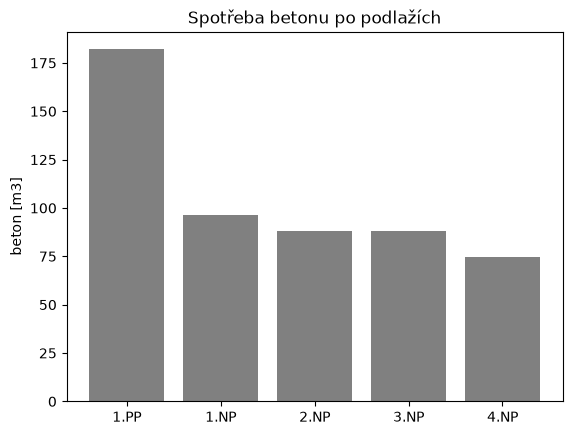

In [3]:
podlazi = ["1.PP", "1.NP", "2.NP", "3.NP", "4.NP"]
beton = [182.0, 96.5, 88.0, 88.0, 74.5]      # m3

plt.bar(podlazi, beton, color="gray")
plt.ylabel("beton [m3]")
plt.title("Spotřeba betonu po podlažích")
plt.show()

**Histogram** `plt.hist` dostane jen hodnoty. Rozdělí je do přihrádek
(`bins`) a nakreslí, kolik hodnot padlo do každé:

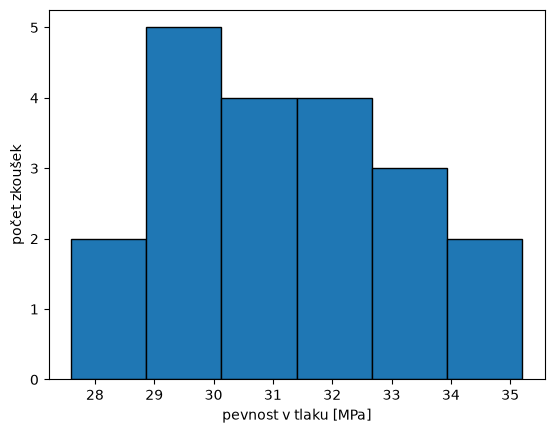

In [4]:
pevnosti = [31.2, 29.8, 33.5, 30.1, 28.7, 32.4, 34.0, 30.9, 27.6, 31.8,
            33.1, 29.4, 30.6, 32.0, 35.2, 28.9, 31.5, 30.3, 32.7, 29.9]   # MPa

plt.hist(pevnosti, bins=6, edgecolor="black")
plt.xlabel("pevnost v tlaku [MPa]")
plt.ylabel("počet zkoušek")
plt.show()

## 3. Graf s více osami: `plt.subplots()`

Funkce `plt.něco()` kreslí do grafu, který si `plt` pamatuje jako "aktuální".
Pro jeden graf to stačí. Pro víc grafů v jednom obrázku je přehlednější druhý
zápis: `plt.subplots()` vrátí **obrázek** a **osy** a kreslí se metodami os.
Dvě návratové hodnoty a metody objektů znáte z lekce 6.

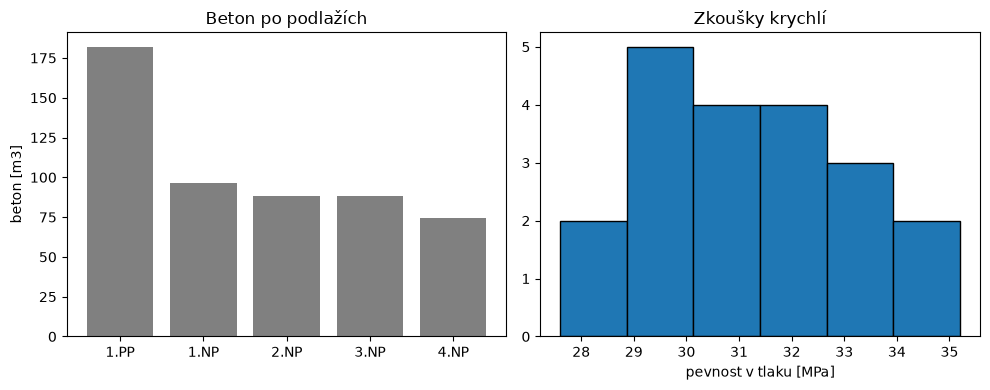

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))    # 1 radek, 2 sloupce

ax1.bar(podlazi, beton, color="gray")
ax1.set_ylabel("beton [m3]")
ax1.set_title("Beton po podlažích")

ax2.hist(pevnosti, bins=6, edgecolor="black")
ax2.set_xlabel("pevnost v tlaku [MPa]")
ax2.set_title("Zkoušky krychlí")

fig.tight_layout()       # at se popisky neprekryvaji
plt.show()

Metody os se jmenují skoro stejně jako funkce `plt`, jen popisky mají
předponu `set_`:

| `plt` | osy `ax` |
|---|---|
| `plt.plot(x, y)` | `ax.plot(x, y)` |
| `plt.xlabel("...")` | `ax.set_xlabel("...")` |
| `plt.title("...")` | `ax.set_title("...")` |
| `plt.legend()` | `ax.legend()` |

Dál budeme používat `fig, ax = plt.subplots()` i pro jeden graf. Je pak
jasné, kam se kreslí.

### Problém: průběh momentu

Prostý nosník o rozpětí `L` se spojitým zatížením `q` má ohybový moment

`M(x) = q * x * (L - x) / 2`

Na hladkou křivku potřebujeme hodně bodů, třeba 201. Se seznamy to jde,
ale každý výpočet znamená další cyklus:

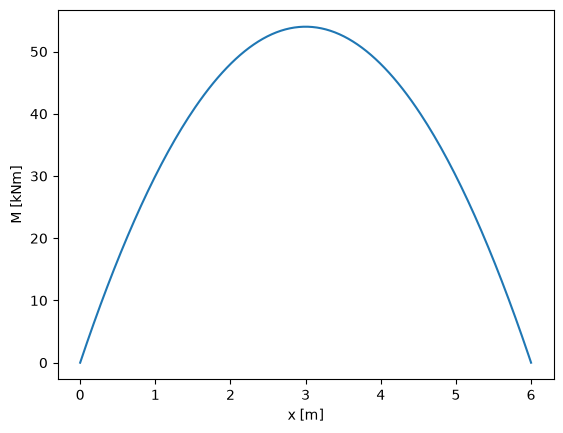

In [6]:
L = 6.0       # m, rozpeti
q = 12.0      # kN/m
n = 201

x_seznam = [i * L / (n - 1) for i in range(n)]
M_seznam = [q * xi * (L - xi) / 2 for xi in x_seznam]

fig, ax = plt.subplots()
ax.plot(x_seznam, M_seznam)
ax.set_xlabel("x [m]")
ax.set_ylabel("M [kNm]")
plt.show()

A teď k momentu od zatížení přičteme moment od vlastní tíhy. Sčítání
seznamů ale neznamená sčítání čísel:

In [7]:
print([1, 2, 3] + [10, 20, 30])     # spoji seznamy
print([1, 2, 3] * 2)                # zopakuje seznam

[1, 2, 3, 10, 20, 30]
[1, 2, 3, 1, 2, 3]


Na každou operaci "prvek po prvku" tedy potřebujeme další cyklus nebo
`zip`. Přesně tohle řeší NumPy.

## 4. NumPy: pole místo seznamu

Základem NumPy je **pole** (`np.array`). Vypadá jako seznam, ale aritmetika
se provádí **prvek po prvku**:

In [8]:
a = np.array([1.0, 2.0, 3.0])
b = np.array([10.0, 20.0, 30.0])

print(a + b)
print(a * 2)
print(a ** 2)
print(1 / a)

[11. 22. 33.]
[2. 4. 6.]
[1. 4. 9.]
[1.         0.5        0.33333333]


In [9]:
print(type(a))
print(a.dtype)     # typ prvku, v poli maji vsechny prvky stejny typ
print(a.shape)     # rozmery pole
print(len(a), a[0], a[-1], a[1:])    # indexovani a vyrezy jako u seznamu

<class 'numpy.ndarray'>
float64
(3,)
3 1.0 3.0 [2. 3.]


| | seznam `list` | pole `np.array` |
|---|---|---|
| typy prvků | libovolné, i různé | jeden typ pro všechny (`dtype`) |
| `+`, `*` | spojení, opakování | sčítání, násobení prvek po prvku |
| velikost | `append` přidává prvky | pevná |
| rychlost | pomalý cyklus v Pythonu | rychlý výpočet uvnitř NumPy |
| použití | cokoli, i texty a objekty | čísla a výpočty |

## 5. `linspace` a výpočet na celém poli

`np.linspace(start, konec, pocet)` vytvoří rovnoměrně rozložené body
**včetně** konce. Moment nosníku je pak jediný řádek, stejný jako vzorec
na papíře:

In [10]:
x = np.linspace(0, L, 201)     # 201 bodu od 0 do L vcetne

M_q = q * x * (L - x) / 2          # moment od zatizeni q
V_q = q * (L / 2 - x)              # posouvajici sila

g = 25 * 0.3 * 0.6                 # kN/m, vlastni tiha tramu 300 x 600 mm
M_g = g * x * (L - x) / 2
M_celkem = M_q + M_g               # soucet prvek po prvku

print(x[:4])
print(M_celkem[:4])

[0.   0.03 0.06 0.09]
[0.       1.477575 2.9403   4.388175]


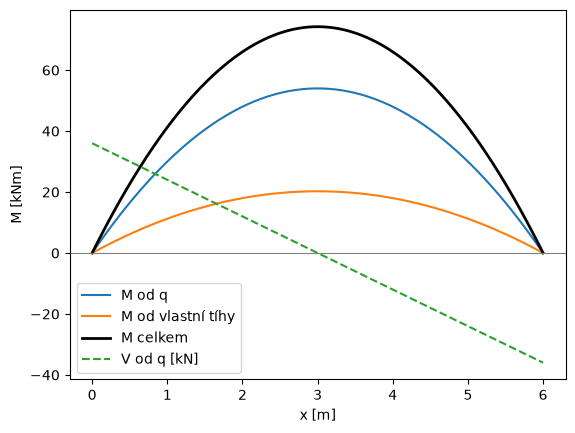

In [11]:
fig, ax = plt.subplots()
ax.plot(x, M_q, label="M od q")
ax.plot(x, M_g, label="M od vlastní tíhy")
ax.plot(x, M_celkem, color="black", linewidth=2, label="M celkem")
ax.plot(x, V_q, linestyle="--", label="V od q [kN]")
ax.axhline(0, color="gray", linewidth=0.8)     # vodorovna cara v y = 0
ax.set_xlabel("x [m]")
ax.set_ylabel("M [kNm]")
ax.legend()
plt.show()

Matplotlib bere pole stejně jako seznamy.

Druhý způsob, jak vytvořit řadu čísel, je `np.arange(start, konec, krok)`.
Funguje jako `range`, ale umí i desetinný krok, a stejně jako `range`
**nezahrnuje konec**:

In [12]:
print(np.arange(0, 1, 0.25))       # zadany krok
print(np.linspace(0, 1, 5))        # zadany pocet bodu

[0.   0.25 0.5  0.75]
[0.   0.25 0.5  0.75 1.  ]


Pro body na ose grafu je bezpečnější `linspace`: víte přesně, kolik bodů
dostanete, a konec v nich je.

**Proč NumPy, když to jde i se seznamy?** Kromě kratšího zápisu je výpočet
uvnitř NumPy mnohem rychlejší. `%timeit` je příkaz notebooku, který buňku
spustí mnohokrát a změří průměrný čas:

In [13]:
n = 1_000_000
x_seznam = [i / n for i in range(n)]
x_pole = np.linspace(0, 1, n)

%timeit [xi * (1 - xi) for xi in x_seznam]
%timeit x_pole * (1 - x_pole)

53.9 ms ± 2.43 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


4.71 ms ± 677 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


## 6. Matematické funkce a agregace

Funkce z modulu `math` umí jen jedno číslo. NumPy má stejné funkce
(`np.sqrt`, `np.sin`, `np.exp`, `np.abs`, ...) a ty počítají s celým
polem najednou:

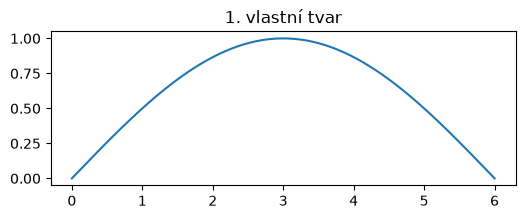

In [14]:
tvar = np.sin(np.pi * x / L)       # 1. vlastni tvar kmitani prosteho nosniku

fig, ax = plt.subplots(figsize=(6, 2))
ax.plot(x, tvar)
ax.set_title("1. vlastní tvar")
plt.show()

**Agregace** shrnou celé pole do jednoho čísla. Jsou to metody pole:

In [15]:
print(f"max M  = {M_celkem.max():.2f} kNm")
print(f"min M  = {M_celkem.min():.2f} kNm")
print(f"prumer = {M_celkem.mean():.2f} kNm")

i = M_celkem.argmax()             # index maxima, ne maximum
print(f"maximum je v bode {i}, x = {x[i]} m")

print(f"max |V| = {np.abs(V_q).max():.1f} kN")
print(f"kontrola (q + g) * L**2 / 8 = {(q + g) * L**2 / 8:.2f} kNm")

max M  = 74.25 kNm
min M  = 0.00 kNm
prumer = 49.25 kNm
maximum je v bode 100, x = 3.0 m
max |V| = 36.0 kN
kontrola (q + g) * L**2 / 8 = 74.25 kNm


| Metoda | Vrátí |
|---|---|
| `a.max()`, `a.min()` | největší, nejmenší prvek |
| `a.argmax()`, `a.argmin()` | **index** největšího, nejmenšího prvku |
| `a.sum()`, `a.mean()` | součet, průměr |
| `a.std()` | směrodatnou odchylku |
| `a.round(2)` | pole zaokrouhlené na 2 místa |

`argmax` je užitečnější, než vypadá. Nejde jen o to, jak velký je moment,
ale i **kde** je. Index pak použijeme v jiném poli: `x[i]`.

## 7. Logické masky

Porovnání pole s číslem neprovede jedno porovnání, ale porovná **každý
prvek**. Výsledkem je pole `True`/`False`, kterému se říká **maska**:

In [16]:
M_Rd = 60.0          # kNm, unosnost prurezu

nevyhovi = M_celkem > M_Rd
print(nevyhovi[52:62])
print(nevyhovi.dtype)

[False False False False False  True  True  True  True  True]
bool


S maskou se dají dělat tři věci:

1. **spočítat**, kolik prvků platí; `True` se počítá jako 1
2. **vybrat** prvky jiného pole tam, kde maska platí: `x[maska]`
3. **přiřadit** hodnotu jen do vybraných prvků: `a[maska] = hodnota`

In [17]:
print("bodu nad unosnosti:", nevyhovi.sum())

x_nevyhovi = x[nevyhovi]
print(f"nevyhovuje od x = {x_nevyhovi.min():.2f} m do x = {x_nevyhovi.max():.2f} m")

bodu nad unosnosti: 87
nevyhovuje od x = 1.71 m do x = 4.29 m


Maska se hodí i do grafu. `fill_between` vybarví plochu mezi dvěma křivkami,
s argumentem `where` jen tam, kde maska platí:

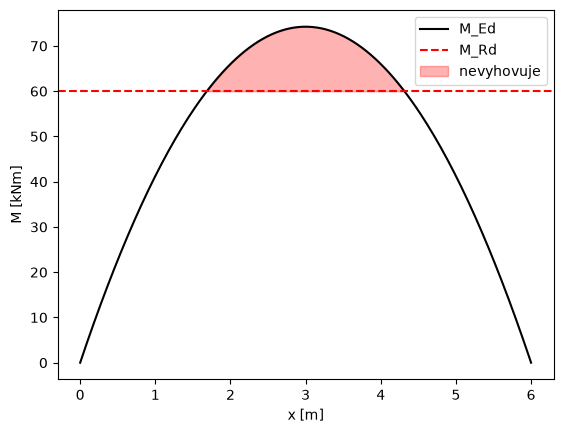

In [18]:
fig, ax = plt.subplots()
ax.plot(x, M_celkem, color="black", label="M_Ed")
ax.axhline(M_Rd, color="red", linestyle="--", label="M_Rd")
ax.fill_between(x, M_celkem, M_Rd, where=nevyhovi, color="red", alpha=0.3,
                label="nevyhovuje")
ax.set_xlabel("x [m]")
ax.set_ylabel("M [kNm]")
ax.legend()
plt.show()

Více podmínek se spojuje operátory `&` (a zároveň) a `|` (nebo). Každé
porovnání musí být **v závorce**. Slova `and` a `or` s poli nefungují
(viz Časté chyby):

In [19]:
stred = (x >= 2) & (x <= 4)
print(f"v prostredni tretine je M od {M_celkem[stred].min():.1f} do {M_celkem[stred].max():.1f} kNm")

v prostredni tretine je M od 66.2 do 74.2 kNm


**Přiřazení maskou** nahrazuje cyklus s `if`. Pracovní diagram oceli
z oddílu 2 tentokrát spočítáme, ne vyjmenujeme. Pružně-plastická ocel:
napětí roste s přetvořením, dokud nedosáhne meze kluzu, pak už neroste.

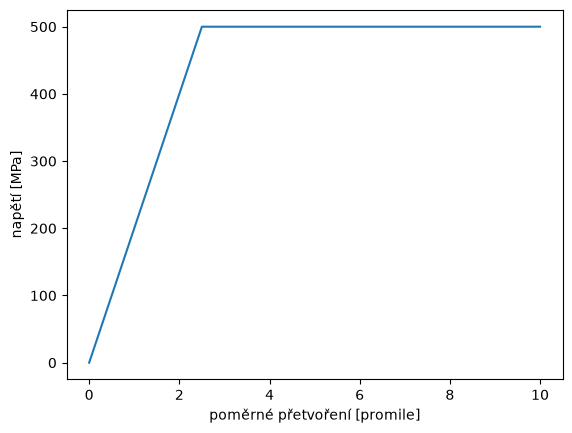

In [20]:
E = 200_000       # MPa
f_y = 500         # MPa

eps = np.linspace(0, 0.01, 101)
sigma = E * eps
sigma[sigma > f_y] = f_y          # nad mezi kluzu napeti neroste

fig, ax = plt.subplots()
ax.plot(eps * 1000, sigma)
ax.set_xlabel("poměrné přetvoření [promile]")
ax.set_ylabel("napětí [MPa]")
plt.show()

## 8. 2D pole

Pole může mít víc rozměrů. 2D pole je tabulka čísel: řádky a sloupce.
Indexuje se **jednou dvojicí** `[radek, sloupec]` a výřezy fungují v obou
směrech.

Příklad: snímek fasády z termokamery. Každý prvek pole je teplota jednoho
bodu povrchu. Snímek si vyrobíme sami:

In [21]:
T = np.full((40, 60), 4.0)        # 40 radku x 60 sloupcu, vsude 4 degC

T[10:22, 8:20] = 11.0             # okno vlevo
T[10:22, 40:52] = 11.0            # okno vpravo
T[30, :] = 8.0                    # tepelny most: stropni deska, cely radek 30
T[:, 0] = 7.0                     # tepelny most: napojeni na sousedni dum, cely sloupec 0

print(T.shape)
print(T[5, 30], T[15, 10], T[30, 5], T[20, 0])    # stena, okno, deska, napojeni

(40, 60)
4.0 11.0 8.0 7.0


2D pole se dobře kreslí jako mapa barev funkcí `imshow`. Řádek 0 je nahoře,
stejně jako na fotce:

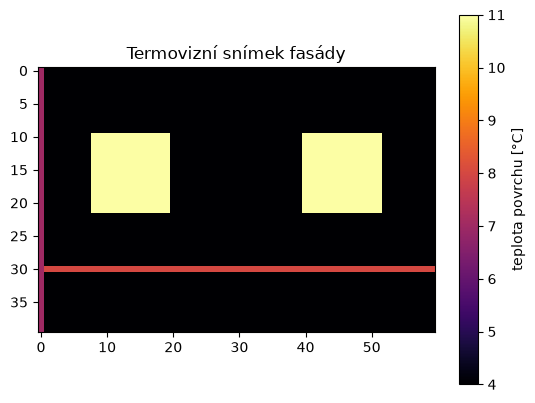

In [22]:
fig, ax = plt.subplots()
obr = ax.imshow(T, cmap="inferno")
fig.colorbar(obr, label="teplota povrchu [°C]")
ax.set_title("Termovizní snímek fasády")
plt.show()

Masky fungují i ve 2D. Jaká část fasády je teplejší než 6 °C, tedy kde
uniká teplo?

In [23]:
teple = T > 6
print(f"teplych bodu: {teple.sum()} z {T.size}")
print(f"podil plochy: {teple.mean() * 100:.1f} %")     # prumer z True/False = podil True

teplych bodu: 387 z 2400
podil plochy: 16.1 %


## 9. Náhodná čísla

Pevnost betonu není jedno číslo. Každá zkouška vyjde trochu jinak. Norma
proto pracuje s **charakteristickou pevností** `f_ck`: hodnotou, pod kterou
leží jen 5 % výsledků (5% kvantil).

NumPy umí náhodná čísla z různých rozdělení. Nejdřív se vytvoří **generátor**.
Číslo `seed` určí, jaká čísla vyjdou: se stejným seedem vyjdou pokaždé
stejná, takže výsledek jde zopakovat.

In [24]:
rng = np.random.default_rng(seed=42)

# C30/37: prumerna pevnost 38 MPa, smerodatna odchylka 5 MPa
f_c = rng.normal(38.0, 5.0, size=10_000)

print(f_c[:5].round(1))
print(f"prumer {f_c.mean():.1f} MPa, smerodatna odchylka {f_c.std():.2f} MPa")

[39.5 32.8 41.8 42.7 28.2]
prumer 37.9 MPa, smerodatna odchylka 5.03 MPa


charakteristicka pevnost f_ck = 29.6 MPa
pod 30 MPa vyslo 5.8 % vzorku


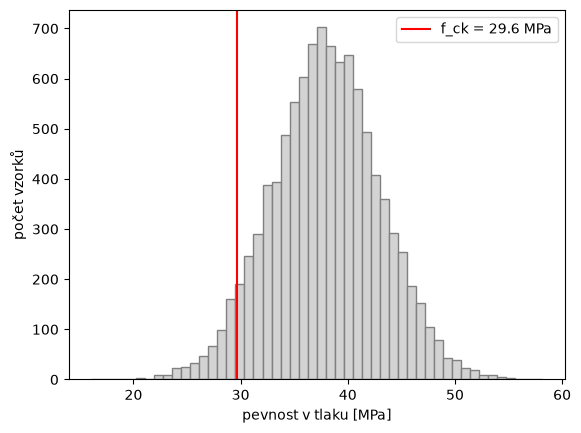

In [25]:
f_ck = np.percentile(f_c, 5)                     # 5% kvantil
podil_pod_30 = (f_c < 30).mean()                 # maska + prumer = podil

print(f"charakteristicka pevnost f_ck = {f_ck:.1f} MPa")
print(f"pod 30 MPa vyslo {podil_pod_30 * 100:.1f} % vzorku")

fig, ax = plt.subplots()
ax.hist(f_c, bins=50, color="lightgray", edgecolor="gray")
ax.axvline(f_ck, color="red", label=f"f_ck = {f_ck:.1f} MPa")
ax.set_xlabel("pevnost v tlaku [MPa]")
ax.set_ylabel("počet vzorků")
ax.legend()
plt.show()

Tomuto postupu se říká **metoda Monte Carlo**: místo složitého vzorce
nasimulujeme tisíce případů a výsledek spočítáme z nich. Ve cvičení tak
porovnáte dva dodavatele betonu.

| Funkce generátoru | Vrátí |
|---|---|
| `rng.normal(prumer, odchylka, size=n)` | normální rozdělení |
| `rng.uniform(od, do, size=n)` | rovnoměrné rozdělení |
| `rng.integers(od, do, size=n)` | celá čísla, `do` nezahrnuje |
| `rng.choice(seznam, size=n)` | náhodný výběr z prvků |

## 10. Časté chyby

**Seznam místo pole.** Seznam se při `*` opakuje, pole násobí:

In [26]:
sily = [10, 20, 30]
print(sily * 2)
print(np.array(sily) * 2)

[10, 20, 30, 10, 20, 30]
[20 40 60]


**Funkce z `math` na pole.** `math.sqrt` umí jen jedno číslo, na pole patří
`np.sqrt`:

In [27]:
import math

plochy = np.array([4.0, 9.0, 16.0])
math.sqrt(plochy)

TypeError: only 0-dimensional arrays can be converted to Python scalars

**`and` místo `&`.** Python neví, jestli je celé pole "pravda", a skončí
chybou. Správně `(x > 1) & (x < 2)`, se závorkami:

In [28]:
x > 1 and x < 2

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

**Výřez pole není kopie.** U seznamu vytvoří výřez nový seznam. U pole je
výřez jen jiný pohled na stejná data. Změna výřezu změní původní pole:

In [29]:
a = np.array([1, 2, 3, 4])
zacatek = a[:2]
zacatek[0] = 99
print(a)                  # zmenilo se i a

b = np.array([1, 2, 3, 4])
zacatek = b[:2].copy()    # skutecna kopie
zacatek[0] = 99
print(b)

[99  2  3  4]
[1 2 3 4]


**Pole celých čísel.** Pole vytvořené z celých čísel má `dtype` `int`
a desetinné číslo se do něj při přiřazení potichu ořízne:

In [30]:
a = np.array([1, 2, 3])
a[0] = 2.7
print(a, a.dtype)

a = np.array([1.0, 2.0, 3.0])     # s desetinnou teckou je dtype float
a[0] = 2.7
print(a, a.dtype)

[2 2 3] int64
[2.7 2.  3. ] float64


**Graf se ve skriptu nezobrazí.** V notebooku se graf ukáže sám, ve skriptu
spuštěném přes `uv run` je potřeba na konci zavolat `plt.show()`.

## Shrnutí

| Zápis | Význam |
|---|---|
| `import numpy as np`, `import matplotlib.pyplot as plt` | obvyklé importy |
| `plt.plot(x, y, label=...)` | čárový graf |
| `plt.bar`, `plt.hist`, `plt.imshow` | sloupce, histogram, mapa barev |
| `fig, ax = plt.subplots()` | obrázek a osy; kreslí se `ax.plot(...)` |
| `ax.set_xlabel`, `ax.set_title`, `ax.legend()` | popisky a legenda |
| `ax.axhline(y)`, `ax.axvline(x)` | vodorovná, svislá čára |
| `ax.fill_between(x, y1, y2, where=maska)` | vybarvená plocha |
| `np.array(seznam)` | pole ze seznamu |
| `np.linspace(od, do, n)` | `n` bodů včetně konce |
| `np.arange(od, do, krok)` | řada s krokem, bez konce |
| `np.full((r, s), hodnota)` | 2D pole vyplněné hodnotou |
| `a + b`, `a * 2`, `np.sin(a)` | výpočet prvek po prvku |
| `a.max()`, `a.argmax()`, `a.mean()` | agregace |
| `a > 5` | maska `True`/`False` |
| `a[maska]`, `a[maska] = 0` | výběr a přiřazení maskou |
| `(a > 1) & (a < 2)` | spojení podmínek |
| `T[r, s]`, `T[2:5, :]` | indexování a výřezy 2D pole |
| `rng = np.random.default_rng(seed)` | generátor náhodných čísel |
| `np.percentile(a, 5)` | 5% kvantil |

Co si odnést:

* graf vzniká postupně: data, popisky, legenda, `plt.show()`
* pro víc grafů a pro přehlednost `fig, ax = plt.subplots()`
* pole počítá prvek po prvku, takže vzorec z papíru se přepíše jedním řádkem
  bez cyklu
* masky nahrazují cyklus s `if`: spočítat, vybrat, přiřadit
* výřez pole je pohled, ne kopie
* Monte Carlo: nasimulovat hodně případů a výsledek spočítat z nich

V lekci 9 přidáme Pandas: tabulky, ve kterých je každý sloupec pole NumPy.

## Ukázka: co Python ještě umí

*Tahle část není látka do testu. Nemusíte rozumět každému řádku.*

Balíček `anastruct` řeší prutové konstrukce metodou konečných prvků. Uvnitř
používá právě NumPy na výpočet a Matplotlib na kreslení. Instalace: `uv add
anastruct`.

Nejdřív náš prostý nosník: rozpětí 6 m a zatížení 12 kN/m. Ručně jsme
spočítali `M_max = q * L**2 / 8 = 54 kNm`.

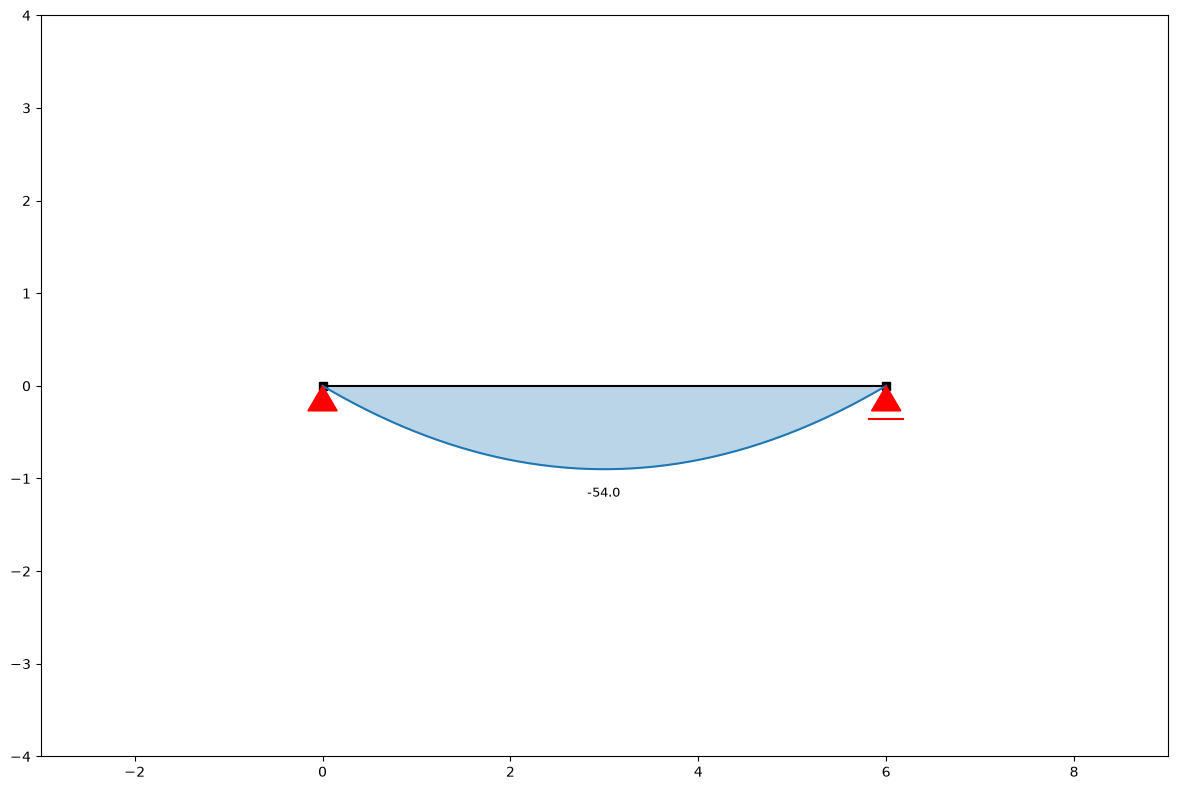

In [31]:
from anastruct import SystemElements

nosnik = SystemElements()
nosnik.add_element(location=[[0, 0], [6, 0]])
nosnik.add_support_hinged(node_id=1)
nosnik.add_support_roll(node_id=2)
nosnik.q_load(q=-12, element_id=1)      # zaporne = dolu
nosnik.solve()
nosnik.show_bending_moment()

Vyšlo 54 kNm. Znaménko a strana, na kterou se moment kreslí, jsou
konvence programu.

To samé zvládneme ručně. Program se ale vyplatí u konstrukce, kterou ručně
počítat nechceme: rám se dvěma vetknutými sloupy, svislým zatížením na příčli
a větrem.

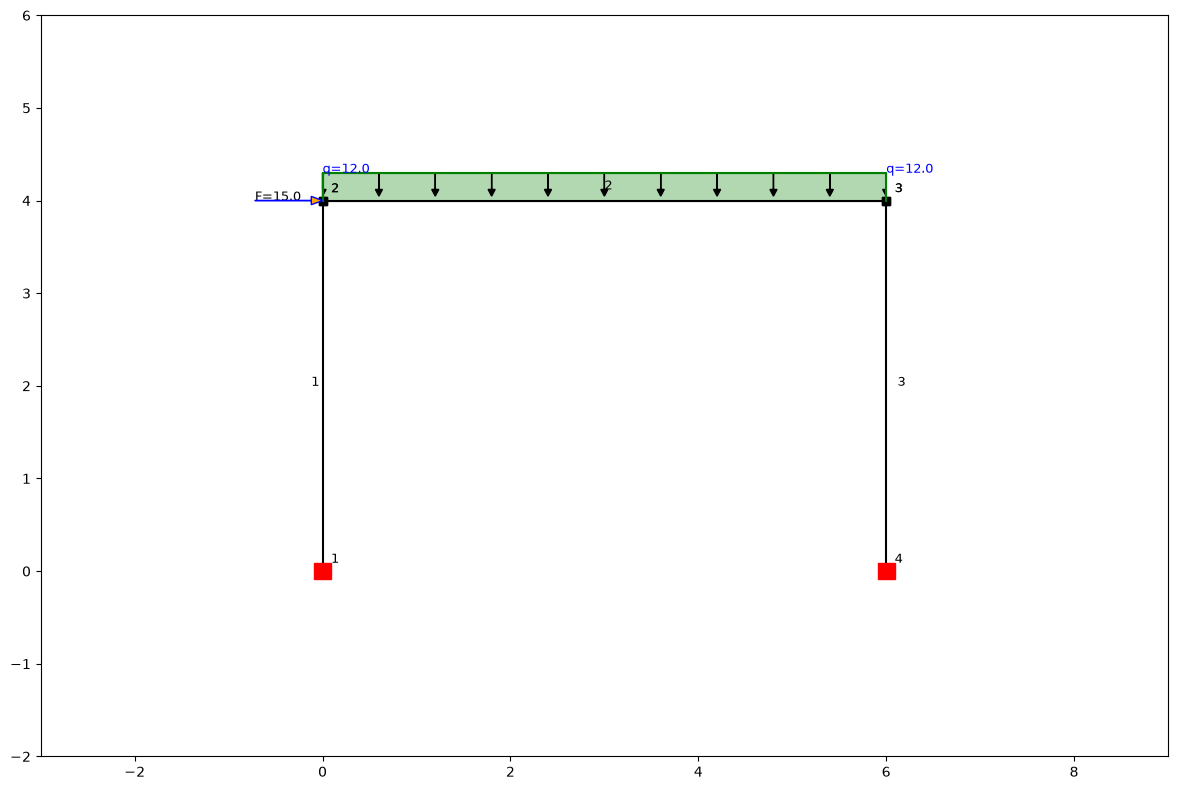

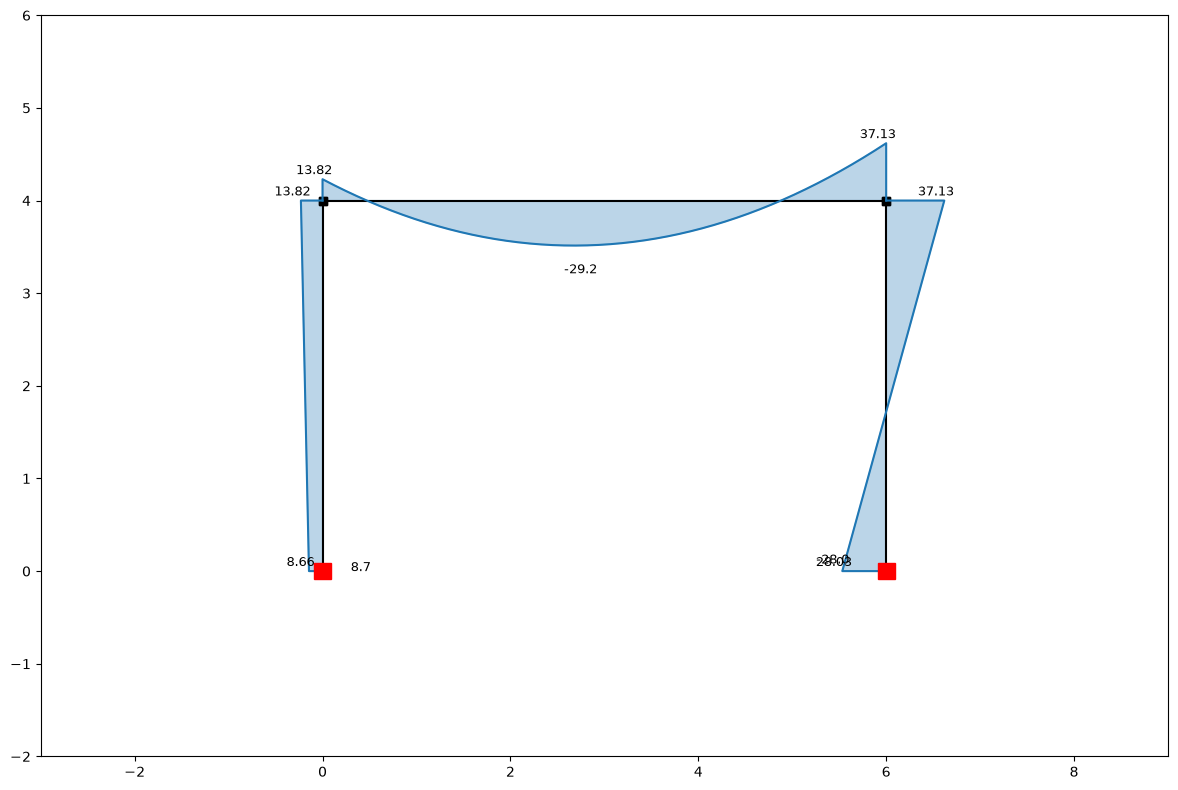

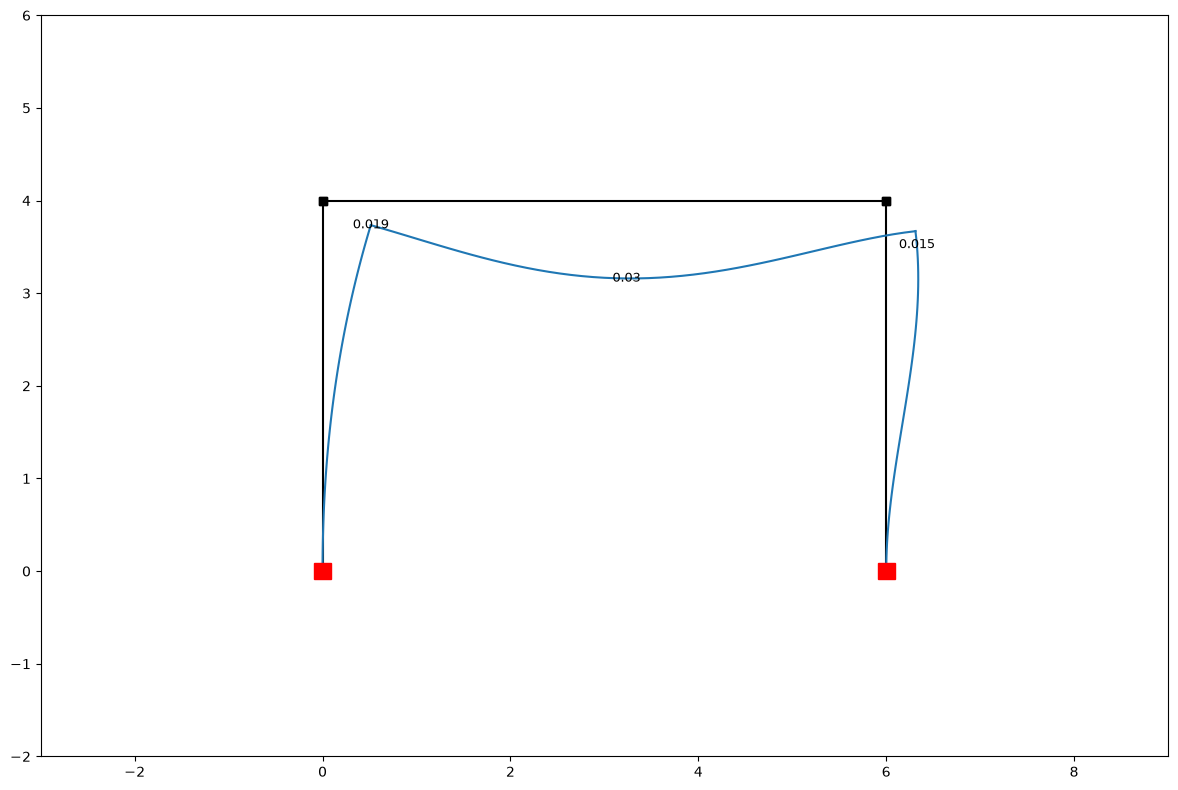

In [32]:
ram = SystemElements()
ram.add_element(location=[[0, 0], [0, 4]])      # levy sloup
ram.add_element(location=[[0, 4], [6, 4]])      # pricel
ram.add_element(location=[[6, 4], [6, 0]])      # pravy sloup
ram.add_support_fixed(node_id=1)
ram.add_support_fixed(node_id=4)
ram.q_load(q=-12, element_id=2)
ram.point_load(node_id=2, Fx=15)                # vitr 15 kN

ram.solve()
ram.show_structure()
ram.show_bending_moment()
ram.show_displacement()

Změna jednoho čísla, třeba výšky sloupů nebo síly od větru, přepočítá celý
rám i všechny diagramy. Spojení s `for` cyklem z lekce 4 dává parametrickou
studii: sto variant rámu za pár sekund.